# Predicting Heart Disease from the CDC BRFSS 2023 Health Survey

This notebook compares traditional machine learning (scikit-learn) with deep learning
(TensorFlow/Keras with `tf.data`) on one question: from a person's survey answers,
can we flag who has been told they have had a heart attack or coronary heart disease?

**Sections**

1. Setup and reproducibility
2. Loading the raw data
3. Defining the target
4. Class balance and what it implies for evaluation
5. Feature selection: what is kept and what is deliberately excluded
6. Cleaning the survey codes
7. Empirical leakage screen
8. Sanity checks and engineered features

9. Train / validation / test split
10. Preprocessing pipeline
11. Experiment protocol and logging
12. Traditional machine learning experiments

13. Deep learning: the `tf.data` input pipeline
14. Deep learning experiments (Keras Sequential and Functional APIs)
15. Learning curves for the deep models

16. Final evaluation on the held-out test set
17. Error analysis, subgroups and saved models
18. Learning curves against training-set size
19. Which answers drive the predictions

## 1. Setup and reproducibility

Everything random in this notebook uses one seed so another person gets the same numbers.
The project root is added to the path so the reusable code in `src/` can be imported.

In [1]:
import sys, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import SEED, TARGET, TARGET_SOURCES, load_raw, define_target

random.seed(SEED)
np.random.seed(SEED)
print("seed:", SEED)

seed: 42


## 2. Loading the raw data

The file is the CDC's original 2023 annual BRFSS release, read without any cleaning.
It is about 1.2 GB, so loading takes roughly a minute and a half. The raw file is not
stored on GitHub; the README explains where to download it.

In [2]:
raw = load_raw()
print(f"rows: {raw.shape[0]:,}   columns: {raw.shape[1]}")

rows: 433,323   columns: 350


The rubric asks for at least 20,000 raw rows; the file is far above that. The 350 columns
are survey questions, derived indicators, and survey-design variables. Most of them will
not be used as predictors, and that selection is done carefully in a later section.

## 3. Defining the target

Two questions in the survey ask whether a doctor ever told the respondent they had
a heart attack (`CVDINFR4`) or coronary heart disease (`CVDCRHD4`). The codes are
1 = yes, 2 = no, 7 = don't know, 9 = refused, and blanks. A "7" or "9" looks like a
valid number to a model, so it has to be handled explicitly. Let us look at how often each code appears.

In [3]:
codes = pd.DataFrame({c: raw[c].value_counts(dropna=False) for c in TARGET_SOURCES}).fillna(0).astype(int)
codes.index = codes.index.map(lambda v: "blank" if pd.isna(v) else int(v))
codes

,CVDINFR4,CVDCRHD4
2,407304,405638
1,23451,23454
7,2314,3936
9,251,292
blank,3,3


Rule used: a respondent is **positive** if they said yes to either question, and
**negative** only if they said no to both. Anyone else (don't know, refused, blank)
has an unknown true label, so those rows are dropped instead of guessed.
A person who said yes to one question and "don't know" to the other is still positive, because the yes alone is enough.

In [4]:
df = define_target(raw)
dropped = len(raw) - len(df)
print(f"rows kept: {len(df):,}   rows dropped (label unknown): {dropped:,} ({dropped/len(raw):.1%})")

rows kept: 428,738   rows dropped (label unknown): 4,585 (1.1%)


## 4. Class balance

Before any model is trained, the share of positives decides how results must be read.

heart_disease
no heart disease    392427
heart disease        36311

positive rate: 8.47%
accuracy of always predicting 'no disease': 91.53%


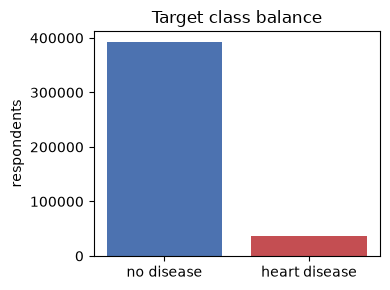

In [5]:
counts = df[TARGET].value_counts().sort_index()
rate = df[TARGET].mean()
print(counts.rename({0: "no heart disease", 1: "heart disease"}).to_string())
print()
print(f"positive rate: {rate:.2%}")
print(f"accuracy of always predicting 'no disease': {1 - rate:.2%}")

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(["no disease", "heart disease"], counts.values, color=["#4c72b0", "#c44e52"])
ax.set_ylabel("respondents")
ax.set_title("Target class balance")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "class_balance.png", dpi=150)
plt.show()

**Interpretation.** The positive class is a small minority, so a model that always answers
"no disease" is right about nine times out of ten while finding nobody who is actually ill.
Accuracy is therefore a misleading headline here. The project reports precision, recall,
ROC-AUC and precision-recall AUC, and uses stratified splits so each split keeps the same
positive rate.

## 5. Feature selection

The file has 350 columns, but most of them cannot or should not be used to predict heart
disease. I sorted every column by asking three questions.

1. **Is it a property of the person?** Interview dates, identifiers, and sampling weights describe how the survey was run, not who answered.
2. **Was it asked of everyone?** Optional modules (cancer screening, caregiving, childhood experiences, COVID) are blank for 50 to 99 percent of people by design, which would make the model learn which state you live in.
3. **Could it leak the answer?** A variable that is a consequence of having a heart event, such as heart medication, would let the model cheat. In a real screening setting that information is not available before diagnosis.

The table below lists what was excluded and why. The 37 variables that remain describe demographics, general health, diagnosed conditions that are known risk factors, functional limitations, and health behaviours.

In [6]:
from src.features import EXCLUDED, NOMINAL_FEATURES, BINARY_FEATURES, NUMERIC_FEATURES, ENGINEERED, clean_features

pd.set_option("display.max_colwidth", 110)
pd.DataFrame({"why excluded": EXCLUDED}).rename_axis("column(s)")

,why excluded
column(s),
_MICHD,Derived by the CDC from the same two questions as the target; it is the answer.
CVDINFR4,One of the two target questions.
CVDCRHD4,One of the two target questions.
CVDSTRK3,"Stroke is a downstream outcome of the same vascular disease, not a risk factor a screener would know in ad..."
BPMEDS1,"Blood-pressure medication: a treatment that often follows a heart event, and asked only of people already ..."
CHOLMED3,Cholesterol medication (statins): commonly started after a heart event.
"ASPIRIN, HASYMP*, STRSYMP*, FIRSTAID",Heart-attack and stroke knowledge/prevention module; closely tied to the outcome and over 90% blank.
"_STATE, FMONTH, IDATE, SEQNO, _PSU, DISPCODE",Interview administration and identifiers.
"_LLCPWT, _LLCPWT2, _STSTR, _STRWT, _RAWRAKE, _WT2RAKE","Survey sampling weights and strata, not properties of the person."


## 6. Cleaning the survey codes

BRFSS stores "don't know" as 7 and "refused" as 9 (77 and 99 for numeric questions). A model would read
a 9 as a very large value. `clean_features` converts those codes to missing (NaN), recodes yes/no answers
to 1/0, turns "88 days" into 0 days, and rescales BMI, which the CDC stores multiplied by 100.

Imputation, scaling and encoding are **not** done here. They are fitted on the training split only,
inside the model pipeline, so no information from the test set leaks into training.

In [7]:
X_all = clean_features(df, engineer=False)
y = df[TARGET]
print(f"features: {X_all.shape[1]}   rows: {X_all.shape[0]:,}")

missing = (X_all.isna().mean() * 100).round(1).sort_values(ascending=False)
missing[missing > 0].to_frame("% missing")

features: 37   rows: 428,738


,% missing
income,19.8
high_cholesterol,12.6
bmi,9.3
heavy_drinker,7.5
smoking_status,5.3
difficulty_errands,4.4
has_insurance,4.2
difficulty_walking,4.1
difficulty_concentrating,4.1
difficulty_dressing,4.0


Most variables are missing in under 5 percent of rows, which is easy to handle. Four stand out:
`income` (19.8 percent, because many people decline to say), `high_cholesterol` (12.6 percent, a question
not asked in part of the questionnaire), `bmi` (9.3 percent, usually unreported height or weight) and
`heavy_drinker` (7.5 percent). Missingness itself can carry information, since people who skip the income
question are not a random sample, so the pipeline will add missing-value indicators next to the imputed
columns instead of silently filling the gaps.

A quick check that no unknown-codes survived cleaning:

In [8]:
checks = {
    "binary features only 0/1/NaN": X_all[BINARY_FEATURES].stack().isin([0, 1]).all(),
    "unwell days between 0 and 30": X_all[["physical_unwell_days", "mental_unwell_days"]].stack().between(0, 30).all(),
    "BMI in a plausible range (12-100)": X_all["bmi"].dropna().between(12, 100).all(),
    "age_group between 1 and 13": X_all["age_group"].dropna().between(1, 13).all(),
}
pd.Series(checks, name="passed")

binary features only 0/1/NaN         True
unwell days between 0 and 30         True
BMI in a plausible range (12-100)    True
age_group between 1 and 13           True
Name: passed, dtype: bool

## 7. Empirical leakage screen

Reasoning about leakage is not enough, so I also measured it. For each variable on its own, I mapped each
answer to the heart-disease rate among people who gave it, and computed the ROC-AUC of that single column.
An AUC near 0.5 means no signal; a value above about 0.85 for one survey question would be suspicious.
This is an in-sample screen (slightly optimistic), meant to flag outliers, not to rank features.
The variables I excluded are scored too, for contrast.

In [9]:
from sklearn.metrics import roc_auc_score

def single_feature_auc(x: pd.Series, y: pd.Series) -> float:
    x = x.fillna(-1)
    if x.nunique() <= 200:                      # map each level to its observed positive rate
        x = x.map(y.groupby(x).mean())
    auc = roc_auc_score(y, x)
    return max(auc, 1 - auc)

kept = {c: single_feature_auc(X_all[c], y) for c in X_all.columns}
excluded_cols = ["_MICHD", "CVDSTRK3", "BPMEDS1", "CHOLMED3"]
excl = {f"{c} (excluded)": single_feature_auc(df[c], y) for c in excluded_cols}

screen = pd.Series({**kept, **excl}, name="single-feature AUC").sort_values(ascending=False).round(3)
screen.to_frame()

,single-feature AUC
_MICHD (excluded),1.000
age_group,0.741
CHOLMED3 (excluded),0.713
employment,0.707
general_health,0.707
BPMEDS1 (excluded),0.696
blood_pressure_status,0.682
high_cholesterol,0.648
arthritis,0.640
difficulty_walking,0.631


**Interpretation.** `_MICHD` scores 1.0: the CDC built it from the two target questions, so any model
given that column would be perfect and worthless. That one is caught empirically.

The other exclusions are not caught by this screen, and it is worth being honest about that. The two
medication variables score 0.70 and 0.71, similar to age (0.74), and stroke scores only 0.57. A single-column
AUC cannot tell "predictive because it is a risk factor" from "predictive because it follows the disease".
Those variables are excluded on reasoning about timing: a person is put on statins or blood-pressure
medication often as a result of a cardiac event, which a screening tool could not know beforehand.
The effect of that decision is measured later as an ablation instead of being assumed.

Among the variables kept, age is the strongest single signal (0.74), followed by employment (0.71, mostly
retirement status, so partly an age proxy) and general health (0.71). Nothing in the kept set is in the leakage zone,
and the modest values (most are between 0.50 and 0.65) show that no single survey answer separates the classes.
That is the reason combining many weak signals in a model is worth testing at all.

## 8. Sanity checks and engineered features

Two quick checks against what medicine expects: heart disease should rise steeply with age and
with worse self-rated health.

In [10]:
check = pd.DataFrame({
    "age_group": X_all["age_group"],
    "general_health": X_all["general_health"],
    "y": y,
})
age_labels = {1: "18-24", 3: "30-34", 5: "40-44", 7: "50-54", 9: "60-64", 11: "70-74", 13: "80+"}
by_age = check.groupby("age_group")["y"].mean().mul(100).round(1)
by_age.index = [f"{int(i)} ({age_labels[int(i)]})" if int(i) in age_labels else str(int(i)) for i in by_age.index]
print("heart disease rate (%) by age group")
print(by_age.to_string())
print()
print("heart disease rate (%) by self-rated general health (1 excellent ... 5 poor)")
print(check.groupby("general_health")["y"].mean().mul(100).round(1).to_string())

heart disease rate (%) by age group
1 (18-24)      0.7
2              0.9
3 (30-34)      1.1
4              1.5
5 (40-44)      2.2
6              3.2
7 (50-54)      5.0
8              7.4
9 (60-64)      9.3
10            11.0
11 (70-74)    14.5
12            17.6
13 (80+)      21.4

heart disease rate (%) by self-rated general health (1 excellent ... 5 poor)
general_health
1.0     2.2
2.0     4.3
3.0     8.6
4.0    17.3
5.0    29.5


The rate climbs from 0.7 percent in the youngest group to 21.4 percent, roughly one in five, among
people 80 and over. By self-rated health it rises from 2.2 percent for "excellent" to 29.5 percent for
"poor", a thirteen-fold difference. Both match clinical expectation, so the cleaned data behaves as it should.

**Engineered features.** Three summary features were added: `n_conditions` (count of diagnosed conditions),
`n_limitations` (count of functional limitations) and `unwell_days_total`. They compress many sparse yes/no
answers into one dense signal that linear models can use directly. Whether they actually help is tested as a
labelled experiment later, with and without them, so the claim is evidence-based and not assumed.

In [11]:
X = clean_features(df, engineer=True)
print("final feature table:", X.shape)
print("engineered:", ENGINEERED)
X[ENGINEERED].describe().loc[["mean", "min", "max"]].round(2)

final feature table: (428738, 40)
engineered: ['n_conditions', 'n_limitations', 'unwell_days_total']


,n_conditions,n_limitations,unwell_days_total
mean,1.91,0.51,8.73
min,0.00,0.00,0.00
max,10.00,6.00,60.00


## 9. Train / validation / test split

The data is divided once, here, and every experiment in this notebook, traditional or deep, uses these same three parts.

| Part | Share | Used for |
|---|---|---|
| Train | 70% | fitting models |
| Validation | 15% | comparing experiments, tuning hyperparameters, choosing the decision threshold |
| Test | 15% | one final measurement of the chosen models; never used to make a decision |

The split is **stratified**, so each part keeps the same 8.5 percent positive rate. With a minority class this
rare, an unstratified split could give one part noticeably fewer positives and make comparisons unfair.
A fixed seed makes the split identical on every run.

In [12]:
from src.experiment import split_data, build_preprocessor, run_experiment, results_table

data = split_data(X, y)
for part in ("train", "val", "test"):
    yy = data[f"y_{part}"]
    print(f"{part:<6} rows: {len(yy):>8,}   positives: {int(yy.sum()):>6,}   positive rate: {yy.mean():.2%}")

train  rows:  300,116   positives: 25,418   positive rate: 8.47%
val    rows:   64,311   positives:  5,447   positive rate: 8.47%
test   rows:   64,311   positives:  5,446   positive rate: 8.47%


## 10. Preprocessing pipeline

Models cannot read NaN, and different kinds of columns need different treatment, so the pipeline handles
three groups separately:

- **Numeric** (age group, BMI, unwell days, engineered counts): median imputation, a missing-value flag column, then standardisation so no feature dominates only because its scale is larger.
- **Binary** (yes/no answers): most-frequent imputation plus a missing-value flag.
- **Nominal categories** (race group, marital status, employment and similar): most-frequent imputation plus a flag, then one-hot encoding. Their numeric codes are labels, not quantities, so treating "marital status 5" as larger than "2" would be wrong.

The pipeline is fitted on training rows only. The validation and test rows are transformed with the
statistics learned from training, which is what a real deployment would do and what prevents leakage.

In [13]:
prep = build_preprocessor().fit(data["X_train"])
Xt = prep.transform(data["X_train"])
print("raw feature columns:", data["X_train"].shape[1], "->  model input columns after preprocessing:", Xt.shape[1])

raw feature columns: 40 ->  model input columns after preprocessing: 114


## 11. Experiment protocol and logging

Each experiment is run by one function, so every row of the final results table is produced the same way.

- **ROC-AUC** measures how well the model ranks sick people above healthy ones, independent of any cut-off. Because 91.5 percent of people are healthy, this number can look comfortable even when the model is poor at the minority class.
- **PR-AUC** (average precision) is stricter for rare positives. A model with no skill scores about the positive rate (0.085), not 0.5, so it is the number to watch.
- **Precision, recall and F1** need a decision threshold. The default of 0.5 would flag almost nobody at an 8.5 percent base rate, so the threshold is chosen to maximise F1 **on the validation set** and then frozen.
- **Train versus validation AUC** shows the gap that diagnoses overfitting.

Every run is also written to an offline Weights & Biases log in `experiments/`, and the table is saved to
`experiments/results.csv`, so each number in the report can be traced to a logged run.

## 12. Traditional machine learning experiments

### Experiment 1: majority-class baseline

A model that ignores every input and predicts the overall rate. It sets the floor: anything real must beat it,
and its ROC-AUC of 0.5 confirms that the metric is not being fooled.

In [14]:
from sklearn.dummy import DummyClassifier

exp1 = run_experiment("E01", "Baseline (prior)", DummyClassifier(strategy="prior"), data,
                      params="strategy=prior",
                      observation="Flags everyone as positive, which is the F1-optimal move for a constant score: precision equals the base rate (0.085), recall 1.0. Sets the floor: ROC-AUC 0.5, PR-AUC 0.085.")
results_table()

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E01,Baseline (prior),strategy=prior,40 (with engineered),300116,64311,0.5,0.5,0.0847,0.085,0.0847,1.0,0.1562,1.1,"Flags everyone as positive, which is the F1-optimal move for a constant score: precision equals the base r..."


**Reading Experiment 1.** The baseline does not predict "nobody is sick". Because it gives every person the same
score, the best F1 it can reach is by flagging everyone, which catches every case (recall 1.0) but is right only
8.5 percent of the time. That is a more honest floor than 91.5 percent accuracy: a real model has to beat a
precision of 0.085 at a useful recall, and a PR-AUC of 0.085.

### Experiment 2: logistic regression, default settings

Logistic regression is the standard first model for tabular risk prediction. It is fast and its coefficients
can be read directly, which matters in healthcare. This run uses scikit-learn defaults
(L2 penalty, C = 1.0) with all 40 features, to establish how much a plain linear model can extract.

In [15]:
from sklearn.linear_model import LogisticRegression

exp2 = run_experiment("E02", "Logistic regression", LogisticRegression(C=1.0, max_iter=1000, random_state=SEED),
                      data, params="C=1.0, penalty=l2, class_weight=None",
                      observation="Train and validation AUC are identical (0.850): no overfitting. Hypothesis that model form limits it was tested by E08-E10: non-linear models add at most 0.003 AUC, so the features, not the model, set the ceiling.")
results_table()

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E01,Baseline (prior),strategy=prior,40 (with engineered),300116,64311,0.50,0.5000,0.0847,0.085,0.0847,1.0000,0.1562,1.1,"Flags everyone as positive, which is the F1-optimal move for a constant score: precision equals the base r..."
E02,Logistic regression,"C=1.0, penalty=l2, class_weight=None",40 (with engineered),300116,64311,0.85,0.8499,0.3478,0.205,0.3409,0.5005,0.4056,4.8,Train and validation AUC are identical (0.850): no overfitting. Hypothesis that model form limits it was t...


**Reading Experiment 2.** Logistic regression separates the groups well on ranking (ROC-AUC 0.85) and its PR-AUC
of 0.35 is about four times the baseline's, so there is real signal in these survey answers.

The train and validation AUCs are the same to three decimals, so the model is **not overfitting**. When I first
ran it, the natural explanation for a modest result was high bias: a linear model cannot represent interactions.
The later experiments test that explanation directly, and it does not hold up. Models that can represent
interactions (Experiments 8 to 10) add at most 0.003 AUC. The ceiling therefore seems to come from the information
in the features, not from the form of the model. At the best-F1 threshold it finds about half of the people with
heart disease (recall 0.50), and about one in three of the people it flags is really ill (precision 0.34).

### Experiment 3: logistic regression with class weighting

Only 8.5 percent of rows are positive, so the loss is dominated by healthy people and the model is rewarded for
leaning towards "no disease". `class_weight="balanced"` multiplies each positive row's contribution by roughly the
inverse of the class frequency (about 11x). Everything else is identical to Experiment 2, so any change comes from
the weighting alone.

In [16]:
from sklearn.linear_model import LogisticRegression

exp3 = run_experiment("E03", "Logistic regression (balanced)",
                      LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000, random_state=SEED),
                      data, params="C=1.0, penalty=l2, class_weight=balanced",
                      observation="Same ranking as E02 (ROC-AUC 0.8499 both). Weighting only moves probabilities: the best-F1 threshold jumps 0.21 to 0.72 and F1 is unchanged (0.405). It changes the operating point, not the model's skill.")
results_table().loc[["E03"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E03,Logistic regression (balanced),"C=1.0, penalty=l2, class_weight=balanced",40 (with engineered),300116,64311,0.8501,0.8499,0.3472,0.724,0.3259,0.5346,0.405,5.7,Same ranking as E02 (ROC-AUC 0.8499 both). Weighting only moves probabilities: the best-F1 threshold jumps...


**Reading Experiment 3.** Class weighting did not make the model better at telling sick from healthy: ROC-AUC,
PR-AUC and F1 are all within rounding of Experiment 2. What it changed is the scale of the scores. Because positives
were up-weighted about 11 times, the model behaves as if the two classes were equally common, and the best
threshold moved from 0.21 to 0.72. The precision and recall pair (0.33 and 0.53) is simply a different point on the
same curve.

The practical consequence is for calibration: after weighting, a predicted "0.7" is no longer a 70 percent chance
of disease. That matters for a clinician-facing risk score, so the final model is checked for calibration
separately instead of assuming it.

### Experiment 4: logistic regression without the engineered features

The three engineered features (`n_conditions`, `n_limitations`, `unwell_days_total`) are sums of columns that are
already present. A linear model can form any sum itself, so these features should add nothing for it. This run removes
them to check that prediction, which would be evidence against an unnecessary feature.

In [17]:
exp4 = run_experiment("E04", "Logistic regression, no engineered",
                      LogisticRegression(C=1.0, max_iter=1000, random_state=SEED),
                      data, params="C=1.0, penalty=l2, class_weight=None", use_engineered=False,
                      observation="Identical to E02 (ROC-AUC 0.8498 vs 0.8499, PR-AUC 0.3478 both). The engineered sums are linear combinations of existing columns, so they are redundant for logistic regression, as predicted.")
results_table().loc[["E04"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E04,"Logistic regression, no engineered","C=1.0, penalty=l2, class_weight=None",37 (no engineered),300116,64311,0.85,0.8498,0.3478,0.189,0.3262,0.5346,0.4052,4.2,"Identical to E02 (ROC-AUC 0.8498 vs 0.8499, PR-AUC 0.3478 both). The engineered sums are linear combinatio..."


**Reading Experiment 4.** Removing the three engineered features changed nothing (PR-AUC 0.3478 in both runs, ROC-AUC
differing by 0.0001). That is what the algebra predicts: each is a sum of columns the model already has, and a linear
model can learn any weighted sum on its own. The engineered features are therefore dead weight for this model,
although they may still help a tree-based model, which is tested in Experiment 11.

### Experiment 5: unconstrained decision tree

A single decision tree can model interactions that a linear model cannot. Left unconstrained, it keeps splitting
until each leaf is nearly pure. This run is deliberately the extreme case, to show what high variance looks like
before any regularisation is applied.

In [18]:
from sklearn.tree import DecisionTreeClassifier

exp5 = run_experiment("E05", "Decision tree (unconstrained)",
                      DecisionTreeClassifier(random_state=SEED),
                      data, params="max_depth=None, min_samples_leaf=1", scale=False,
                      observation="Memorises the training data: train AUC 1.00 vs validation 0.59. Predictions are leaf purities of 0 or 1, so the threshold is 1.0. Textbook high variance.")
results_table().loc[["E05"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E05,Decision tree (unconstrained),"max_depth=None, min_samples_leaf=1",40 (with engineered),300116,64311,1.0,0.5911,0.1231,1.0,0.2302,0.2638,0.2459,8.8,"Memorises the training data: train AUC 1.00 vs validation 0.59. Predictions are leaf purities of 0 or 1, s..."


**Reading Experiment 5.** This is the textbook case of overfitting. The tree reaches a training AUC of 1.00 by
memorising individuals, and on unseen people it falls to 0.59, barely better than guessing. The validation threshold
is 1.0 because a fully grown tree outputs only 0 or 1, so it has no useful ranking and its F1 of 0.25 is poor.
The size of that train/validation gap is the variance problem in numbers, and it is the reason every later tree
model is regularised.

### Experiment 6: regularised decision tree

The same model with its growth limited: at most 8 levels deep, and every leaf must contain at least 100 people.
These two settings stop the tree from memorising individuals and force each prediction to rest on a group of
people. Comparing this run with Experiment 5 isolates the effect of regularisation.

In [19]:
exp6 = run_experiment("E06", "Decision tree (regularised)",
                      DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=SEED),
                      data, params="max_depth=8, min_samples_leaf=100", scale=False,
                      observation="Depth 8 and leaf >= 100 shrink the gap to 0.008 and lift validation AUC from 0.59 to 0.836, but it stays below logistic regression (0.850): one tree approximates smooth additive effects with steps.")
results_table().loc[["E06"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E06,Decision tree (regularised),"max_depth=8, min_samples_leaf=100",40 (with engineered),300116,64311,0.844,0.8358,0.3096,0.172,0.2855,0.5853,0.3837,5.1,"Depth 8 and leaf >= 100 shrink the gap to 0.008 and lift validation AUC from 0.59 to 0.836, but it stays b..."


**Reading Experiment 6.** Restricting depth and leaf size cuts the gap between training and validation from 0.41 to
0.008 and raises validation AUC from 0.59 to 0.836. Regularisation turned a useless model into a reasonable one.
It still does not beat logistic regression, however, which suggests that for these data a single tree's step-shaped
splits are a worse approximation of the mostly additive risk pattern than a linear model. Its recall is the highest
of any real model so far (0.59), but at a precision of 0.29.

### Experiment 7: random forest

A random forest averages many decorrelated trees, each trained on a bootstrap sample and a random subset of
features. Averaging reduces the variance that Experiment 5 exposed while keeping the ability to model interactions.
Settings: 200 trees, depth capped at 12, at least 50 people per leaf, square-root feature sampling at each split.

In [20]:
from sklearn.ensemble import RandomForestClassifier

exp7 = run_experiment("E07", "Random forest",
                      RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=50,
                                             max_features="sqrt", n_jobs=-1, random_state=SEED),
                      data, params="n_estimators=200, max_depth=12, min_samples_leaf=50, max_features=sqrt",
                      scale=False, observation="Averaging 200 trees: validation AUC 0.8465, slightly below logistic regression; gap 0.011 so mild variance remains. 7x slower for no gain. Only one configuration tried, so this is not a verdict on forests.")
results_table().loc[["E07"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E07,Random forest,"n_estimators=200, max_depth=12, min_samples_leaf=50, max_features=sqrt",40 (with engineered),300116,64311,0.8573,0.8465,0.3397,0.2,0.337,0.4924,0.4001,37.6,"Averaging 200 trees: validation AUC 0.8465, slightly below logistic regression; gap 0.011 so mild variance..."


**Reading Experiment 7.** Averaging many trees fixes the variance of a single tree (validation AUC 0.8465 versus
0.836), but the forest is still slightly below logistic regression and took seven times as long to fit. Its
train/validation gap of 0.011 indicates that some variance remains. I tried only one configuration, so
this should not be read as "forests are worse here"; it shows that an untuned forest is not an upgrade over a
plain linear model on these features.

### Experiment 8: gradient boosting with default settings

Gradient boosting builds trees one after another, each correcting the errors of the ones before it, which
reduces bias where a random forest mainly reduces variance. `HistGradientBoostingClassifier` bins features into
histograms and is fast on a dataset of this size. This run uses scikit-learn's defaults as a reference point.

In [21]:
from sklearn.ensemble import HistGradientBoostingClassifier

exp8 = run_experiment("E08", "HistGradientBoosting (default)",
                      HistGradientBoostingClassifier(random_state=SEED),
                      data, params="learning_rate=0.1, max_iter=100, max_leaf_nodes=31", scale=False,
                      observation="Default boosting is the first model to beat logistic regression: validation AUC 0.852, F1 0.410, but by only 0.003, about one standard error. Train AUC 0.866 shows mild overfitting (gap 0.014).")
results_table().loc[["E08"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E08,HistGradientBoosting (default),"learning_rate=0.1, max_iter=100, max_leaf_nodes=31",40 (with engineered),300116,64311,0.8656,0.852,0.3475,0.207,0.3328,0.5337,0.41,16.6,"Default boosting is the first model to beat logistic regression: validation AUC 0.852, F1 0.410, but by on..."


**Reading Experiment 8.** The first model to beat logistic regression, though only just: validation ROC-AUC 0.852
against 0.850. For scale, the standard error of an AUC measured on 5,447 positive cases is roughly 0.003 (Hanley and
McNeil), so this difference is about one standard error and should not be treated as decisive on its own. The
training AUC of 0.866 against 0.852 on validation shows a mild gap, so the model is starting to fit noise.

### Experiment 9: gradient boosting, smaller steps and stronger regularisation

Boosting overfits if it takes large steps for too long. This run lowers the learning rate to 0.05, allows up to
600 rounds but stops early when a held-out 10 percent of the training rows stops improving, restricts each tree to
15 leaves, requires 100 people per leaf, and adds L2 penalty. Early stopping uses a slice of the training set, so
the validation set is not consulted for the number of rounds.

In [22]:
exp9 = run_experiment("E09", "HistGradientBoosting (regularised)",
                      HistGradientBoostingClassifier(learning_rate=0.05, max_iter=600, max_leaf_nodes=15,
                                                     min_samples_leaf=100, l2_regularization=1.0,
                                                     early_stopping=True, validation_fraction=0.1,
                                                     n_iter_no_change=20, random_state=SEED),
                      data, params="lr=0.05, max_iter<=600 (early stop), leaves=15, min_leaf=100, l2=1.0",
                      scale=False, observation="Smaller steps and regularisation give the best validation scores (AUC 0.8528, PR-AUC 0.349, F1 0.413) with a smaller gap (0.009). The gain over E08 is within noise, but the model is more stable.")
results_table().loc[["E09"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E09,HistGradientBoosting (regularised),"lr=0.05, max_iter<=600 (early stop), leaves=15, min_leaf=100, l2=1.0",40 (with engineered),300116,64311,0.8621,0.8528,0.3488,0.2,0.3291,0.5557,0.4134,38.7,"Smaller steps and regularisation give the best validation scores (AUC 0.8528, PR-AUC 0.349, F1 0.413) with..."


**Reading Experiment 9.** Smaller steps, shallower trees and a penalty gave the best validation numbers so far
(ROC-AUC 0.8528, PR-AUC 0.349, F1 0.413) and a smaller train/validation gap than the default (0.009 versus 0.014).
As with Experiment 8, the improvement in accuracy is within noise, but the regularised model generalises more
consistently, which is the property that matters when choosing a model. Early stopping used a held-out slice of the
training data, so the validation set did not influence the number of boosting rounds.

### Experiment 10: gradient boosting, deeper trees

The opposite direction from Experiment 9: more capacity per tree (63 leaves, 200 people per leaf) at the same
learning rate. If interactions matter more than variance control, this should win; if the data is mostly noise
around a simple signal, it should not.

In [23]:
exp10 = run_experiment("E10", "HistGradientBoosting (deeper)",
                      HistGradientBoostingClassifier(learning_rate=0.05, max_iter=600, max_leaf_nodes=63,
                                                     min_samples_leaf=200, l2_regularization=1.0,
                                                     early_stopping=True, validation_fraction=0.1,
                                                     n_iter_no_change=20, random_state=SEED),
                      data, params="lr=0.05, max_iter<=600 (early stop), leaves=63, min_leaf=200, l2=1.0",
                      scale=False, observation="More capacity per tree raises train AUC to 0.870 but validation stays at 0.8524; gap 0.018. The extra capacity fits training noise, not extra signal.")
results_table().loc[["E10"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E10,HistGradientBoosting (deeper),"lr=0.05, max_iter<=600 (early stop), leaves=63, min_leaf=200, l2=1.0",40 (with engineered),300116,64311,0.8702,0.8524,0.3485,0.199,0.3274,0.5585,0.4128,30.3,More capacity per tree raises train AUC to 0.870 but validation stays at 0.8524; gap 0.018. The extra capa...


**Reading Experiment 10.** Giving each tree more capacity raised the training AUC to 0.870 and left the validation AUC
at 0.8524, so the gap doubled to 0.018 with nothing gained. More flexible trees fit patterns in the training set
that do not generalise. Experiment 9's regularised configuration is therefore the preferred boosting model, being the
simplest one that achieves the best validation result.

### Taking stock after ten experiments

Every model except the two single trees sits in a narrow band: validation ROC-AUC between 0.846 and 0.853, PR-AUC
near 0.35, and F1 near 0.40 to 0.41. The standard error on these AUCs is about 0.003, so most of the differences among Experiments 2, 3, 4,
8, 9 and 10 are not distinguishable. Three conclusions follow.

1. **The ceiling is the information in the features, not the algorithm.** Changing from a linear model to boosted
   trees with interactions added about 0.003 AUC. This is a statement about 37 self-reported survey answers: they
   say who is at elevated risk, but they cannot say who will have a heart attack.
2. **Regularisation matters for stability, not headline accuracy.** The un-regularised tree (E05) was disastrous,
   while the regularised boosting model (E09) generalised best with the smallest gap.
3. **Cost-benefit favours simple models here.** Logistic regression is within about 0.003 AUC of the best model,
   fits in 10 seconds against 92, and its coefficients can be read by a clinician. That is a real accuracy versus
   interpretability trade-off, and it is argued for in the report.

Two ablations remain: whether the engineered features help the tree model, and how much accuracy the excluded
treatment variables would have added.

### Experiment 11: boosting without the engineered features

Experiment 4 showed the engineered counts are redundant for a linear model. A tree model could in principle use
them, because a single split on `n_conditions` replaces many splits on individual conditions. This run repeats the
best boosting configuration (Experiment 9) with the three features removed.

In [24]:
exp11 = run_experiment("E11", "HistGradientBoosting, no engineered",
                       HistGradientBoostingClassifier(learning_rate=0.05, max_iter=600, max_leaf_nodes=15,
                                                      min_samples_leaf=100, l2_regularization=1.0,
                                                      early_stopping=True, validation_fraction=0.1,
                                                      n_iter_no_change=20, random_state=SEED),
                       data, params="as E09, engineered features removed", scale=False,
                       use_engineered=False, observation="Removing the engineered features moves ROC-AUC 0.8528 to 0.8524 and PR-AUC 0.3488 to 0.3465: within noise. The aggregates add no information a tree cannot build itself.")
results_table().loc[["E09", "E11"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E09,HistGradientBoosting (regularised),"lr=0.05, max_iter<=600 (early stop), leaves=15, min_leaf=100, l2=1.0",40 (with engineered),300116,64311,0.8621,0.8528,0.3488,0.200,0.3291,0.5557,0.4134,38.7,"Smaller steps and regularisation give the best validation scores (AUC 0.8528, PR-AUC 0.349, F1 0.413) with..."
E11,"HistGradientBoosting, no engineered","as E09, engineered features removed",37 (no engineered),300116,64311,0.8612,0.8524,0.3465,0.205,0.3342,0.5390,0.4126,33.3,Removing the engineered features moves ROC-AUC 0.8528 to 0.8524 and PR-AUC 0.3488 to 0.3465: within noise....


**Reading Experiment 11.** Removing the engineered features moved validation ROC-AUC from 0.8528 to 0.8524 and
PR-AUC from 0.349 to 0.347, both well inside noise. A boosted tree can rebuild the same counts from the individual
condition columns with a few splits, so the summaries save the model some work but give it no new information.

The honest conclusion is that these three aggregate features did not improve either model family. I had expected
feature engineering to help, and it is reported as a negative result, not as a success. The final model keeps the
simpler 37-column input for that reason: with no measured benefit, the extra columns are only extra surface area.
Other kinds of engineered feature (for example interactions between age and blood pressure, or banded BMI) were not
tested and remain possible future work.

### Experiment 12: adding the excluded treatment variables

In Section 5 I excluded blood-pressure medication, cholesterol medication and stroke history because they often
follow a heart event, so a screening tool would not know them in advance. A single-column check could not show
leakage, so this experiment measures the effect directly: the same best configuration, with those three variables
added back. If they carry post-diagnosis information, validation performance should rise clearly above the plateau.
The medication variables are coded 1 when the person reports taking the drug and 0 otherwise, because they were only
asked of people already diagnosed with the underlying condition.

In [25]:
X_extra = X.copy()
X_extra["bp_medication"] = (df["BPMEDS1"] == 1).astype(float)
X_extra["cholesterol_medication"] = (df["CHOLMED3"] == 1).astype(float)
X_extra["stroke_history"] = df["CVDSTRK3"].map({1: 1.0, 2: 0.0})

data_extra = split_data(X_extra, y)
assert data_extra["X_val"].index.equals(data["X_val"].index), "split must match the main experiments"

exp12 = run_experiment("E12", "HistGradientBoosting + treatment variables",
                       HistGradientBoostingClassifier(learning_rate=0.05, max_iter=600, max_leaf_nodes=15,
                                                      min_samples_leaf=100, l2_regularization=1.0,
                                                      early_stopping=True, validation_fraction=0.1,
                                                      n_iter_no_change=20, random_state=SEED),
                       data_extra, params="as E09, plus BP medication, cholesterol medication, stroke history",
                       scale=False, extra_binary=("bp_medication", "cholesterol_medication", "stroke_history"),
                       observation="Treatment variables lift ROC-AUC 0.8528 to 0.8660, PR-AUC 0.349 to 0.379 and F1 0.413 to 0.430: real but modest. Excluding them costs about 0.013 AUC; E12 is kept as an upper bound, not the screening model.")
results_table().loc[["E09", "E12"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E09,HistGradientBoosting (regularised),"lr=0.05, max_iter<=600 (early stop), leaves=15, min_leaf=100, l2=1.0",40 (with engineered),300116,64311,0.8621,0.8528,0.3488,0.200,0.3291,0.5557,0.4134,38.7,"Smaller steps and regularisation give the best validation scores (AUC 0.8528, PR-AUC 0.349, F1 0.413) with..."
E12,HistGradientBoosting + treatment variables,"as E09, plus BP medication, cholesterol medication, stroke history",43 (with engineered),300116,64311,0.8747,0.8660,0.3787,0.195,0.3384,0.5880,0.4296,38.4,"Treatment variables lift ROC-AUC 0.8528 to 0.8660, PR-AUC 0.349 to 0.379 and F1 0.413 to 0.430: real but m..."


**Reading Experiment 12.** Adding the three treatment variables raised validation ROC-AUC from 0.8528 to 0.8660,
PR-AUC from 0.349 to 0.379, and F1 from 0.413 to 0.430, with recall up to 0.59 at a slightly higher precision
(0.34). The AUC gain is about four times its standard error, so it is real, and it is the largest improvement over
the plateau of any experiment, larger than the whole gap between logistic regression and boosting. It is still
modest: even with information about treatment, the model only reaches 0.866.

Two readings fit these numbers and the data cannot separate them. Under the first, the variables partly encode
what happened after a cardiac event, which is the leakage concern. Under the second, people are prescribed blood
pressure and cholesterol medication to prevent events, so the variables also carry genuine information about how
severe someone's hypertension or cholesterol is. Probably both contribute.

The decision to exclude them stands on the intended use, not on this result: a screening tool has to work for
people who have no diagnosis yet, so it cannot depend on post-diagnosis treatment. What this experiment adds is the
price of that decision, about 0.013 AUC. The report therefore presents Experiment 9 as the screening model and
Experiment 12 as an upper bound on what the survey can deliver.

## 13. Deep learning: the `tf.data` input pipeline

The neural networks are trained on exactly the same people as the scikit-learn models, in the same split, and
they receive the same cleaned columns. Three details matter for a fair comparison.

- **Same preprocessing.** The identical imputation, missing-value flags, scaling and one-hot encoding is fitted on training rows only and then applied to validation and test rows. Networks are sensitive to feature scale, so the standardisation is not optional here.
- **No engineered features.** Experiments 4 and 11 showed the three engineered columns add nothing, so the networks use the simpler 37-column input.
- **Early stopping without touching validation.** A stratified 10 percent slice of the training rows is held back to decide when to stop training. The validation set stays untouched by every training decision, the same way early stopping was done for gradient boosting in Experiment 9.

The data then flows through a `tf.data` pipeline: tensors are sliced into examples, shuffled with a fixed
seed (training only), grouped into batches of 1,024 and prefetched, so the CPU prepares the next batch while the
current one is being used.

In [26]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import keras
from src.deep import (make_inputs, make_dataset, sequential_mlp, functional_mlp, balanced_class_weight,
                      run_keras_experiment, plot_learning_curves, HISTORIES)

keras.utils.set_random_seed(SEED)
inputs = make_inputs(data)
print(f"model inputs: {inputs['n_features']}")
print(f"fit rows: {len(inputs['X_fit']):,}   early-stopping slice: {len(inputs['X_stop']):,}   "
      f"validation: {len(inputs['X_val']):,}   test: {len(inputs['X_test']):,}")

example_ds = make_dataset(inputs["X_fit"], inputs["y_fit"], batch_size=1024, shuffle=True)
xb, yb = next(iter(example_ds))
print("one batch from the tf.data pipeline:", xb.shape, yb.shape, "| positives in batch:", int(yb.numpy().sum()))

model inputs: 110
fit rows: 270,104   early-stopping slice: 30,012   validation: 64,311   test: 64,311


one batch from the tf.data pipeline: (1024, 110) (1024,) | positives in batch: 95


## 14. Deep learning experiments

Every network ends in a single sigmoid unit and is trained with binary cross-entropy and the Adam optimiser,
with early stopping (patience 5, best weights restored). Each experiment changes one thing relative to an
earlier one, and the results are compared against the best scikit-learn models: logistic regression
(Experiment 2, validation ROC-AUC 0.850) and regularised gradient boosting (Experiment 9, 0.853).

### Experiment 13: Sequential network, two hidden layers

The simplest sensible network, built with the Sequential API: two dense layers of 64 and 32 units with ReLU
activations, no dropout, learning rate 0.001, batch size 1,024. It is the deep-learning counterpart of the plain
logistic regression baseline and answers whether non-linear feature combinations learned by a network find
signal that boosting did not.

In [27]:
exp13 = run_keras_experiment("E13", "Keras Sequential 64-32", lambda n: sequential_mlp(n, units=(64, 32)),
                             inputs, params="units=64-32, dropout=0, lr=1e-3, batch=1024",
                             observation="Slightly above logistic regression (ROC-AUC 0.8522 vs 0.8499), level with boosting; stopped at epoch 8 of 13. Held-out loss flattens after epoch 2 while train loss keeps falling: mild overfitting, small AUC gap (0.003).")
results_table().loc[["E13"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E13,Keras Sequential 64-32,"units=64-32, dropout=0, lr=1e-3, batch=1024; best epoch 8 of 13",110 model inputs (no engineered),270104,64311,0.8554,0.8522,0.3494,0.201,0.3275,0.5506,0.4107,21.9,"Slightly above logistic regression (ROC-AUC 0.8522 vs 0.8499), level with boosting; stopped at epoch 8 of ..."


**Reading Experiment 13.** A small two-layer network reached a validation ROC-AUC of 0.852, marginally above
logistic regression (0.850) and level with gradient boosting (0.853), after about 18 seconds of training. The
training and validation AUCs differ by only 0.003, so overfitting is mild in the metric. The learning curve in
Section 15 shows the early sign of it, though: the held-out loss stops improving after about the second epoch while
the training loss keeps falling. Early stopping restored the weights from epoch 8, the best point on the held-out slice.

### Experiment 14: Functional network with batch normalisation and dropout

The Functional API makes the architecture explicit and lets layers be combined freely. This network is wider and
deeper (128, 64 and 32 units), adds batch normalisation after each dense layer to stabilise training, and
dropout of 0.3 to randomly silence a third of the units during training so the network cannot lean on any single
one. Compared with Experiment 13, this changes capacity and regularisation together.

In [28]:
exp14 = run_keras_experiment("E14", "Keras Functional 128-64-32 + BN + dropout",
                             lambda n: functional_mlp(n, units=(128, 64, 32), dropout=0.3, batch_norm=True),
                             inputs, params="units=128-64-32, BN, dropout=0.3, lr=1e-3, batch=1024",
                             observation="Wider with batch norm and dropout: ROC-AUC 0.8531, the best deep result, but only +0.0009 over E13 for 4x the fit time. Train and held-out loss overlap, so variance is controlled.")
results_table().loc[["E14"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E14,Keras Functional 128-64-32 + BN + dropout,"units=128-64-32, BN, dropout=0.3, lr=1e-3, batch=1024; best epoch 15 of 20",110 model inputs (no engineered),270104,64311,0.8569,0.8531,0.3497,0.215,0.3274,0.5451,0.4091,91.1,"Wider with batch norm and dropout: ROC-AUC 0.8531, the best deep result, but only +0.0009 over E13 for 4x ..."


**Reading Experiment 14.** More capacity with batch normalisation and dropout produced the best deep-learning
validation AUC (0.8531), but the improvement over the plain network is 0.0009, well below the roughly 0.003 standard
error, and it cost four times the training time. The regularisation did exactly what it was meant to do: the
training and held-out loss curves lie on top of each other for all 20 epochs, so there is no visible variance
problem. (Keras measures the training loss with dropout switched on, which keeps that curve slightly higher than the
model's behaviour at prediction time.) The result lands on the same plateau as the other model families.

### Experiment 15: the same network with class weighting

Only 8.5 percent of the training examples are positive. Here the loss is reweighted so each positive example
counts about 5.9 times and each negative about 0.55 times, which pushes the network to take the minority class
seriously during training. In logistic regression (Experiment 3) this changed the threshold and not the ranking.
This run tests whether a network, which can reshape its internal representation, behaves differently.

In [29]:
exp15 = run_keras_experiment("E15", "Keras Functional 128-64-32, class-weighted",
                             lambda n: functional_mlp(n, units=(128, 64, 32), dropout=0.3, batch_norm=True),
                             inputs, params="as E14 + class_weight balanced (pos ~5.9, neg ~0.55)",
                             class_weight=balanced_class_weight(inputs["y_fit"]),
                             observation="Class weighting leaves ranking unchanged (ROC-AUC 0.8529 vs 0.8531) and moves the threshold from 0.22 to 0.73, as in E03. Held-out loss is erratic because weighting distorts the probability scale.")
results_table().loc[["E15"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E15,"Keras Functional 128-64-32, class-weighted","as E14 + class_weight balanced (pos ~5.9, neg ~0.55); best epoch 10 of 15",110 model inputs (no engineered),270104,64311,0.8547,0.8529,0.3513,0.731,0.3502,0.4977,0.4111,70.8,Class weighting leaves ranking unchanged (ROC-AUC 0.8529 vs 0.8531) and moves the threshold from 0.22 to 0...


**Reading Experiment 15.** As with logistic regression, class weighting did not improve the ranking (AUC 0.8529
against 0.8531) and moved the best threshold from 0.22 to 0.73. The erratic held-out loss in the learning curve
should be read with that in mind. Weighted training inflates the predicted probabilities, so the unweighted loss on
the held-out slice swings with the scale of the scores more than with the quality of the ranking. Early stopping
watches that loss, so its choice of epoch is less trustworthy for this run than for the others. Its PR-AUC of 0.351
is the highest of any model that uses only the screening features, but it exceeds Experiment 9 by 0.0025, which
is within noise.

### Experiment 16: Sequential network with a high learning rate

Learning rate is the most influential optimiser setting. This run repeats Experiment 13 with the learning rate
raised tenfold to 0.01, to see whether larger steps converge faster or make training unstable. The learning curve in
the next section shows which.

In [30]:
exp16 = run_keras_experiment("E16", "Keras Sequential 64-32, lr=0.01", lambda n: sequential_mlp(n, units=(64, 32)),
                             inputs, params="units=64-32, dropout=0, lr=1e-2, batch=1024",
                             learning_rate=1e-2, observation="A 10x higher learning rate does not diverge: the best held-out loss comes at epoch 3 instead of 8, then it overfits sooner. ROC-AUC 0.8514, slightly worse than E13.")
results_table().loc[["E16"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E16,"Keras Sequential 64-32, lr=0.01","units=64-32, dropout=0, lr=1e-2, batch=1024; best epoch 3 of 8",110 model inputs (no engineered),270104,64311,0.8509,0.8514,0.3459,0.197,0.3356,0.5214,0.4083,13.6,"A 10x higher learning rate does not diverge: the best held-out loss comes at epoch 3 instead of 8, then it..."


**Reading Experiment 16.** A tenfold larger learning rate did not make training unstable. The network reached its
best held-out loss at epoch 3 instead of epoch 8, and from there the held-out curve rises while the training curve
keeps falling, so it began to overfit sooner. Early stopping ended the run after epoch 8. The result is slightly
worse than Experiment 13 (AUC 0.8514 against 0.8522, PR-AUC 0.346 against 0.349): larger steps cross the minimum
more coarsely and settle at a marginally worse point. The faster rate saves time but costs a little accuracy, so
0.001 remains the better setting.

### Experiment 17: wide network with strong regularisation

The final variation pushes capacity up (256, 128 and 64 units) and counters it with heavier dropout (0.5) and an
L2 weight penalty of 0.0001. It tests whether a much larger network can extract more from the same 37 inputs once
overfitting is controlled.

In [31]:
exp17 = run_keras_experiment("E17", "Keras Functional 256-128-64, dropout 0.5 + L2",
                             lambda n: functional_mlp(n, units=(256, 128, 64), dropout=0.5, l2=1e-4, batch_norm=True),
                             inputs, params="units=256-128-64, BN, dropout=0.5, l2=1e-4, lr=1e-3, batch=1024",
                             observation="Largest network with dropout 0.5 and L2: train and held-out curves coincide (AUC gap 0.001) but ROC-AUC 0.8528 is no better than E13, at 9x the fit time. Capacity is not the limit.")
results_table().loc[["E17"]]

,model,params,features,n_train,n_val,train_roc_auc,val_roc_auc,val_pr_auc,threshold,precision,recall,f1,fit_seconds,observation
exp_id,,,,,,,,,,,,,,
E17,"Keras Functional 256-128-64, dropout 0.5 + L2","units=256-128-64, BN, dropout=0.5, l2=1e-4, lr=1e-3, batch=1024; best epoch 25 of 30",110 model inputs (no engineered),270104,64311,0.8537,0.8528,0.3486,0.247,0.3355,0.5265,0.4099,188.5,Largest network with dropout 0.5 and L2: train and held-out curves coincide (AUC gap 0.001) but ROC-AUC 0....


**Reading Experiment 17.** The largest network, with half its units dropped at every step and an L2 weight penalty,
shows train and validation AUC within 0.001 of each other and learning curves that coincide. Regularisation removed
the variance completely, yet validation AUC (0.8528) is no better than the small 64-32 network, and the run took
nine times as long. A much larger and fully regularised network matching a small one is direct evidence that
capacity is not what limits performance on these data.

## 15. Learning curves for the deep models

Each panel plots the training loss and the loss on the held-out early-stopping slice for one run. The dotted line
marks the epoch whose weights were kept. A widening gap between the lines indicates overfitting; two lines that
stay together and flatten indicate that the model has reached the limit of what it can learn.

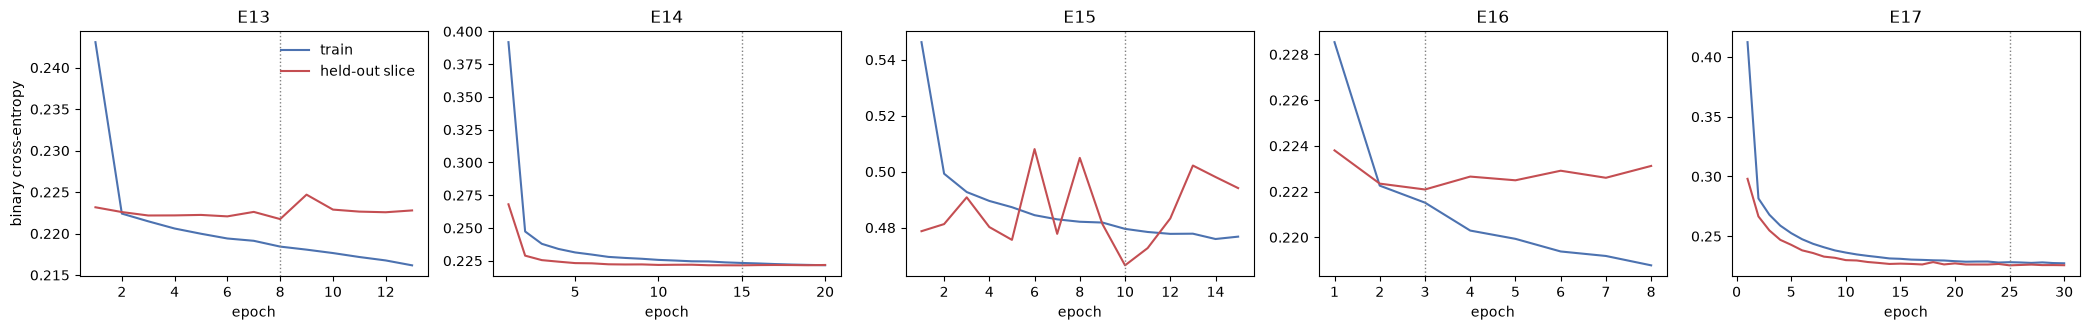

In [32]:
plot_learning_curves(["E13", "E14", "E15", "E16", "E17"],
                     path=PROJECT_ROOT / "reports" / "figures" / "dl_learning_curves.png")

**Reading the learning curves.** Four patterns appear.

In Experiment 13 the training loss keeps decreasing while the held-out loss goes flat after the second epoch. This
is the standard onset of overfitting. It stays mild because the training set is large (about 270,000 rows) and the
network is small.

In Experiments 14 and 17 batch normalisation and dropout close the gap entirely: the two curves overlap and flatten
together. There is no variance left to remove, so training for longer or adding more regularisation would not help.

In Experiment 16 the high learning rate shortens the path to the minimum, but the held-out curve begins to rise
after epoch 3, so the network overfits sooner than at the lower rate. It does not diverge.

In Experiment 15 the held-out loss is erratic while the training loss is smooth. The cause is the class weighting,
which changes the scale of the predicted probabilities, not any instability in learning.

**Bias and variance.** All five networks have a small gap between training and validation AUC (at most 0.004), so
variance is low, yet none of them exceeds a validation AUC of 0.853. The remaining error is therefore not something
more regularisation or a larger network can fix. It reflects the information that 37 self-reported survey answers
contain about who will develop heart disease.

### Taking stock after the deep-learning experiments

Three different model families now sit within about 0.004 ROC-AUC of each other: logistic regression (0.850),
regularised gradient boosting (0.853) and the best neural network (0.853). The gaps between them are about the size of the
standard error of the metric (roughly 0.003), so none of them can be declared clearly superior on accuracy. They differ
sharply in cost and in how well they can be explained.

| Family | Validation ROC-AUC | PR-AUC | Fit time | Explainable to a clinician? |
|---|---|---|---|---|
| Logistic regression (E02) | 0.850 | 0.348 | about 10 s | Yes: one coefficient per answer |
| Gradient boosting (E09) | 0.853 | 0.349 | about 40 s | Partly: feature importances, SHAP |
| Neural network (E14) | 0.853 | 0.350 | about 70 s | Little without extra tooling |

The practical conclusion is that on these data a deep network buys nothing that a logistic regression does not
already provide. That is itself a finding, and it is argued for in the report, not hidden.

In [33]:
results_table().loc[["E02", "E09", "E12", "E13", "E14", "E15", "E16", "E17"],
                  ["model", "train_roc_auc", "val_roc_auc", "val_pr_auc", "precision", "recall", "f1", "fit_seconds"]]

,model,train_roc_auc,val_roc_auc,val_pr_auc,precision,recall,f1,fit_seconds
exp_id,,,,,,,,
E02,Logistic regression,0.8500,0.8499,0.3478,0.3409,0.5005,0.4056,4.8
E09,HistGradientBoosting (regularised),0.8621,0.8528,0.3488,0.3291,0.5557,0.4134,38.7
E12,HistGradientBoosting + treatment variables,0.8747,0.8660,0.3787,0.3384,0.5880,0.4296,38.4
E13,Keras Sequential 64-32,0.8554,0.8522,0.3494,0.3275,0.5506,0.4107,21.9
E14,Keras Functional 128-64-32 + BN + dropout,0.8569,0.8531,0.3497,0.3274,0.5451,0.4091,91.1
E15,"Keras Functional 128-64-32, class-weighted",0.8547,0.8529,0.3513,0.3502,0.4977,0.4111,70.8
E16,"Keras Sequential 64-32, lr=0.01",0.8509,0.8514,0.3459,0.3356,0.5214,0.4083,13.6
E17,"Keras Functional 256-128-64, dropout 0.5 + L2",0.8537,0.8528,0.3486,0.3355,0.5265,0.4099,188.5


## 16. Final evaluation on the held-out test set

Until this point the test rows were never used: every model choice, threshold and hyperparameter was decided on
the validation set. The three finalists were fixed before looking at the test set, and each is scored on it once.

| Finalist | Why it is included |
|---|---|
| Logistic regression (E02) | the interpretable option and the simplest model |
| Gradient boosting (E09) | the best traditional model on validation |
| Neural network (E14) | the best deep-learning model on validation |

The decision threshold for each model is the one chosen on validation and is **frozen**. Re-tuning it on the test
set would make the numbers optimistic. Square brackets give 95 percent intervals from resampling the 64,311 test
people 300 times, so differences smaller than the interval width should not be over-interpreted.

In [34]:
import joblib, json
from src.experiment import feature_columns
from src.evaluation import (test_summary, paired_bootstrap, plot_roc_pr, plot_confusion, plot_calibration,
                            operating_points, subgroup_table)

FIG = PROJECT_ROOT / "reports" / "figures"
y_test = data["y_test"].to_numpy()
cols = feature_columns(True)

test_proba = {
    "Logistic regression (E02)": exp2["pipeline"].predict_proba(data["X_test"][cols])[:, 1],
    "Gradient boosting (E09)": exp9["pipeline"].predict_proba(data["X_test"][cols])[:, 1],
    "Neural network (E14)": exp14["model"].predict(make_dataset(inputs["X_test"], inputs["y_test"], 4096), verbose=0).ravel(),
}
val_proba = {
    "Logistic regression (E02)": exp2["val_proba"],
    "Gradient boosting (E09)": exp9["val_proba"],
    "Neural network (E14)": exp14["val_proba"],
}
thresholds = {
    "Logistic regression (E02)": exp2["threshold"],
    "Gradient boosting (E09)": exp9["threshold"],
    "Neural network (E14)": exp14["threshold"],
}
summary = test_summary(y_test, test_proba, thresholds)
summary

,ROC-AUC,PR-AUC,Brier,threshold,precision,recall,F1
model,,,,,,,
Logistic regression (E02),"0.847 [0.842, 0.853]","0.350 [0.336, 0.365]",0.0645,0.205,0.335,0.491,0.399
Gradient boosting (E09),"0.851 [0.846, 0.856]","0.351 [0.338, 0.364]",0.0642,0.200,0.323,0.543,0.405
Neural network (E14),"0.850 [0.845, 0.855]","0.353 [0.339, 0.368]",0.0643,0.215,0.325,0.542,0.406


**Reading the test results.** The three finalists are within 0.004 of each other on ROC-AUC (0.847, 0.851 and
0.850) and within 0.003 on PR-AUC (0.350, 0.351 and 0.353). Each is about 0.002 to 0.003 lower than its validation
score. A small and uniform drop is what ordinary selection effects produce, since the best of several validation
runs is slightly flattered by having been picked, and it gives no sign of leakage or of an unusually easy validation
set. The intervals are roughly 0.005 either side of the estimate, which is the precision that 5,446 positive cases
allow.

The Brier score, which penalises poor probability estimates, is 0.064 for all three. A model that always predicted
the 8.5 percent base rate would score 0.0775, so the models are about 17 percent better. At the frozen thresholds,
gradient boosting and the network find 54 percent of cases at 32 to 33 percent precision, while logistic regression
finds 49 percent at 34 percent.

### Are the differences between the finalists real?

Overlapping intervals do not prove two models are equal, because both are measured on the same people. A paired
comparison resamples the same test people for both models and looks at the difference directly.

In [35]:
names = list(test_proba)
pairs = [(names[1], names[0]), (names[2], names[0]), (names[2], names[1])]
rows = []
for a, b in pairs:
    d = paired_bootstrap(y_test, test_proba[a], test_proba[b])
    rows.append({"comparison": f"{a}  minus  {b}",
                 "ROC-AUC difference": f"{d['roc_diff']:+.4f} [{d['roc_lo']:+.4f}, {d['roc_hi']:+.4f}]",
                 "PR-AUC difference": f"{d['pr_diff']:+.4f} [{d['pr_lo']:+.4f}, {d['pr_hi']:+.4f}]"})
pd.DataFrame(rows).set_index("comparison")

,ROC-AUC difference,PR-AUC difference
comparison,,
Gradient boosting (E09) minus Logistic regression (E02),"+0.0038 [+0.0025, +0.0050]","+0.0013 [-0.0027, +0.0045]"
Neural network (E14) minus Logistic regression (E02),"+0.0030 [+0.0019, +0.0041]","+0.0031 [+0.0006, +0.0056]"
Neural network (E14) minus Gradient boosting (E09),"-0.0008 [-0.0017, +0.0001]","+0.0017 [-0.0013, +0.0052]"


**Reading the paired comparison.** Gradient boosting beats logistic regression by 0.0038 ROC-AUC and the network
beats it by 0.0030. Both intervals exclude zero, so the advantage is real. It is also very small: a few thousandths
of an AUC point. Boosting and the network cannot be told apart (difference -0.0008, interval includes zero). On
PR-AUC only the network's edge over logistic regression is distinguishable from zero (+0.0031).

This refines the statement made after the validation experiments, where the gaps were described as within noise.
That judgement used a conservative unpaired standard error. Comparing the models on identical resampled people is a
sharper test, and it shows a small genuine edge for the more flexible models. Whether a 0.004 gain justifies the
extra complexity is a question of value, not of statistics, and it is taken up in the Discussion.

### ROC and precision-recall curves

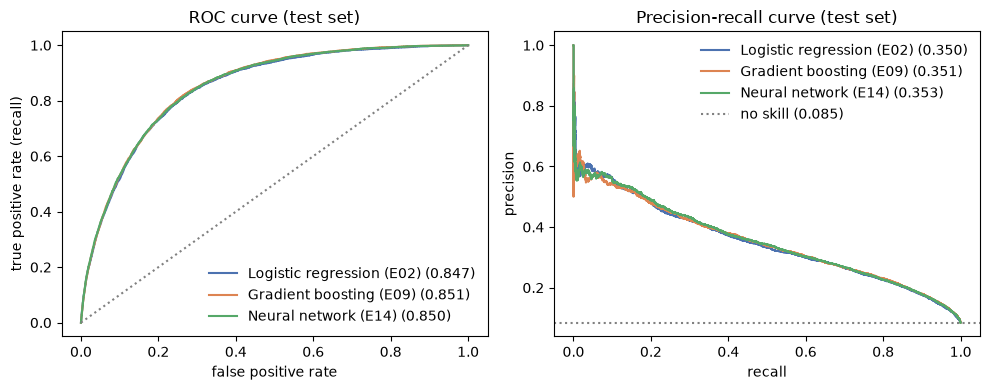

In [36]:
plot_roc_pr(y_test, test_proba, path=FIG / "test_roc_pr.png")

**Reading the curves.** The three ROC curves lie almost on top of each other, which is what a ceiling set by the
features looks like: different algorithms, same ranking quality. All sit far above the diagonal. The precision-recall
curves also overlap, and they are far above the no-skill line at 0.085, but they fall steadily with no knee. There is
no operating point where precision stays high while recall becomes useful; the operating-point table below puts
numbers on this. The jagged section at the far left, where a handful of people with extreme scores decide
the value, is estimation noise and should not be read as a model difference.

### Confusion matrices at the frozen thresholds

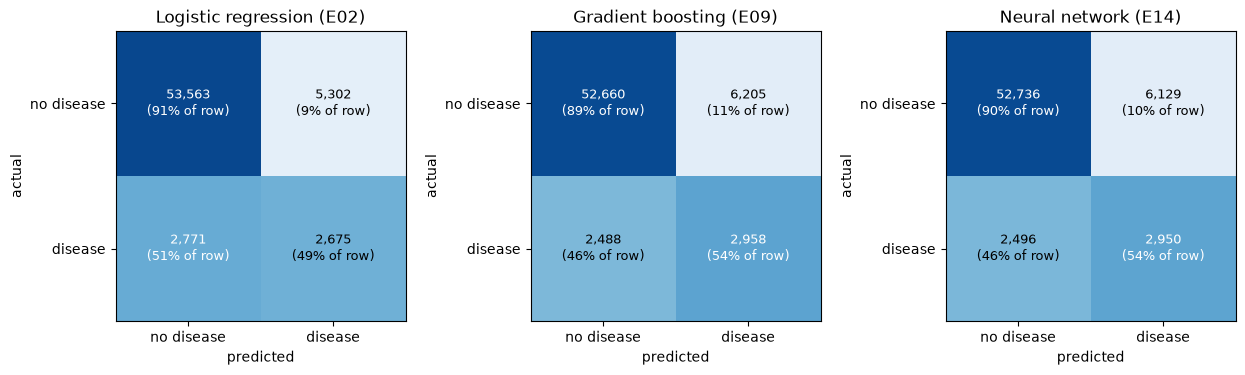

In [37]:
plot_confusion(y_test, test_proba, thresholds, path=FIG / "test_confusion.png")

**Reading the confusion matrices.** At its frozen threshold, gradient boosting flags 9,163 of the 64,311 test
people (14 percent). Of those, 2,958 truly have heart disease and 6,205 do not, so for every case found there are
about two false alarms. It misses 2,488 of the 5,446 people with disease (46 percent). Logistic regression is more
conservative: it raises 5,302 false alarms, 900 fewer, at the price of missing 283 additional cases. The network is
almost identical to boosting (2,950 versus 2,958 cases found).

Which of these is preferable depends on how costly a missed case is compared with an unnecessary follow-up. F1
weighs the two equally, but a screening programme would not, which is why the choice of threshold is examined
separately below.

### Calibration

A risk score is only useful as a probability if "0.20" really means about one person in five. The curve plots,
for ten equal-sized groups of people ordered by predicted risk, the average prediction against the fraction who
actually had heart disease.

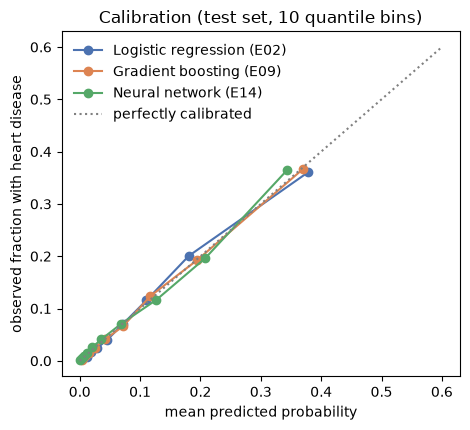

In [38]:
plot_calibration(y_test, test_proba, path=FIG / "test_calibration.png")

**Reading the calibration plot.** All three models track the diagonal closely over the whole range, so a predicted
0.12 corresponds to about 12 percent of such people really having heart disease. This holds even though none of
these three was trained with class weights, which Experiments 3 and 15 showed would have distorted the scale.
Good calibration is what makes the output usable as a risk estimate and not only as a ranking.

The plot also exposes a limit that the AUC hides: the highest-risk tenth of people has an average prediction near
0.37, and about 36 percent of them have the disease. Even at the top of the scale the models are wrong about
two times in three, so they rank people well but cannot say with confidence who is ill.

### Operating points: what each choice of threshold costs

The F1-optimal threshold is a convenient single number, but a real screening programme would pick the threshold
from how many people it can afford to follow up. The table fixes a target recall on the validation set and reports
what happens on the test set for the gradient boosting model.

In [39]:
operating_points(data["y_val"], val_proba["Gradient boosting (E09)"], y_test, test_proba["Gradient boosting (E09)"])

,threshold,recall on test,precision on test,% of people flagged,people flagged per case found
target recall,,,,,
0.5,0.223,0.494,0.341,12.3,2.9
0.7,0.134,0.698,0.267,22.1,3.7
0.8,0.091,0.807,0.228,29.9,4.4
0.9,0.049,0.897,0.181,42.0,5.5


**Reading the operating points.** The thresholds chosen on validation transfer well: a target of 0.5 recall gave
0.49 on the test set and a target of 0.9 gave 0.90. The cost of sensitivity is steep. Finding half of all cases
means flagging 12 percent of the population, with about three people flagged per case found. Finding 90 percent
means flagging 42 percent of everyone, with 5.5 people flagged per case. The ranking is informative but not sharp.

For a screening setting this is the number that matters, more than any AUC. A programme that can only follow up
one person in eight would catch about half of cases. One that wanted to catch nearly all of them would be
reviewing four in ten people, which in practice is no longer a targeted screen.

## 17. Error analysis, subgroups and saved models

### Who is missed?

Aggregate numbers hide who the model fails. For the gradient boosting model at its frozen threshold, the test
people with heart disease split into those it caught (true positives) and those it missed (false negatives). The
table compares their profiles, with healthy people not flagged (true negatives) for reference.

In [40]:
Xt = data["X_test"].copy()
Xt["actual"] = y_test
Xt["pred"] = (test_proba["Gradient boosting (E09)"] >= thresholds["Gradient boosting (E09)"]).astype(int)
Xt["outcome"] = np.select(
    [(Xt.actual == 1) & (Xt.pred == 1), (Xt.actual == 1) & (Xt.pred == 0), (Xt.actual == 0) & (Xt.pred == 0)],
    ["caught (true positive)", "missed (false negative)", "healthy, not flagged (true negative)"], default="false alarm")

profile = Xt.groupby("outcome").agg(
    people=("actual", "size"),
    mean_age_group=("age_group", "mean"),
    mean_general_health=("general_health", "mean"),
    mean_bmi=("bmi", "mean"),
    mean_unwell_days=("physical_unwell_days", "mean"),
    pct_high_cholesterol=("high_cholesterol", lambda s: 100 * s.mean()),
    pct_high_blood_pressure=("blood_pressure_status", lambda s: 100 * (s == 1).mean()),
    pct_diabetes=("diabetes_status", lambda s: 100 * (s == 1).mean()),
    pct_physically_active=("physically_active", lambda s: 100 * s.mean()),
    pct_difficulty_walking=("difficulty_walking", lambda s: 100 * s.mean()),
).round(2)
profile

,people,mean_age_group,mean_general_health,mean_bmi,mean_unwell_days,pct_high_cholesterol,pct_high_blood_pressure,pct_diabetes,pct_physically_active,pct_difficulty_walking
outcome,,,,,,,,,,
caught (true positive),2958,11.15,3.84,29.19,12.65,78.09,86.75,43.71,54.18,54.37
false alarm,6205,11.05,3.64,29.30,11.19,72.85,83.58,38.61,57.59,48.03
"healthy, not flagged (true negative)",52660,7.03,2.41,28.27,3.18,34.97,32.02,8.74,78.75,9.80
missed (false negative),2488,9.56,2.84,28.97,5.25,54.19,59.04,21.86,69.57,22.11


**Reading the error profile.** The people the model catches are visibly burdened: on average in their early
seventies, with 87 percent reporting high blood pressure, 78 percent high cholesterol, 44 percent diabetes and 54
percent difficulty walking. The people it misses look much more like the healthy majority: younger on average
(group 9.6 against 11.2 for those caught), with 59 percent high blood pressure, 22 percent diabetes and 22 percent
difficulty walking, and more of them physically active (70 percent against 54). Their self-rated health, 2.8, is
close to that of healthy people (2.4) and far from the 3.8 of those caught.

In other words, the model finds heart disease that arrives with a visible burden of other conditions and misses
heart disease that does not, because on these 37 questions such people are hard to distinguish from the healthy.
The false alarms, 6,205 of them, look almost the same as the true positives (same age group, 84 percent with high
blood pressure). They are older, hypertensive, diabetic people who did not report a heart event. Some may have
undiagnosed disease or may develop it later, which a cross-sectional survey cannot tell us. What remains is plain
irreducible randomness: two people with the same answers can have different outcomes.

### Does performance differ across groups?

The same frozen threshold is applied inside each subgroup. A model that works well on average can still be much
less sensitive for some people, which matters for anything used on a population.

In [41]:
p = test_proba["Gradient boosting (E09)"]
thr = thresholds["Gradient boosting (E09)"]
ag, sex = Xt["age_group"], Xt["is_female"]
groups = {
    "all": np.ones(len(Xt), dtype=bool),
    "age 18-44": (ag <= 5).to_numpy(),
    "age 45-64": ag.between(6, 9).to_numpy(),
    "age 65+": ag.between(10, 13).to_numpy(),
    "male": (sex == 0).to_numpy(),
    "female": (sex == 1).to_numpy(),
    "general health good or better": (Xt["general_health"] <= 3).to_numpy(),
    "general health fair or poor": (Xt["general_health"] >= 4).to_numpy(),
    "lower income (bands 1-2)": (Xt["income"] <= 2).to_numpy(),
    "no health insurance": (Xt["has_insurance"] == 0).to_numpy(),
}
subgroup_table(y_test, p, thr, groups)

,n,disease rate,% flagged,recall,precision,ROC-AUC
group,,,,,,
all,64311,0.085,14.2,0.543,0.323,0.851
age 18-44,19028,0.013,0.4,0.071,0.247,0.815
age 45-64,19930,0.065,8.6,0.400,0.300,0.831
age 65+,24248,0.158,30.1,0.628,0.329,0.770
male,30157,0.105,20.4,0.637,0.328,0.850
female,34154,0.067,8.8,0.413,0.312,0.844
general health good or better,51901,0.057,7.2,0.348,0.275,0.840
general health fair or poor,12240,0.203,44.1,0.775,0.356,0.782
lower income (bands 1-2),7373,0.140,27.9,0.666,0.335,0.809


**Reading the subgroup results.** Ranking quality is reasonable everywhere, with AUCs between 0.77 and 0.85. The
uneven part is recall at the single threshold, and it follows the base rates. Among people aged 18 to 44 the model
finds only 7 percent of cases and flags 0.4 percent of the group, because almost nobody in that group is predicted
above 0.2. Among those 65 and over it finds 63 percent. Women, who have a lower disease rate (6.7 versus 10.5
percent), have recall of 41 percent compared with 64 percent for men, although the ranking quality is almost the
same (AUC 0.844 against 0.850). People reporting fair or poor health are caught at 78 percent, those in good
health at 35 percent.

Two things follow. First, a single global threshold hides that the model is much less sensitive for younger people
and for women; the same AUC with a group-specific threshold would find more of their cases, at the price of more
false alarms, which is how clinical risk scores are usually applied. Second, discrimination is lowest among the
oldest (0.77), where age has already done most of the work, so the model has the least extra information there.
Because the groups overlap and age, sex and health are related to one another, these subgroup differences are
not adjusted for each other and should be read as descriptive, not as separate causes. The uninsured group is small (3,347 people, about
125 cases), so its lower recall of 29 percent carries wide uncertainty.

### Saved models

The two best models are saved for the shared Drive folder. The network needs its fitted preprocessor too, because
raw survey answers must be transformed exactly as during training. These files are git-ignored by design.

In [42]:
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)
joblib.dump(exp9["pipeline"], MODELS / "best_traditional_hgb_e09.joblib")
exp14["model"].save(MODELS / "best_deep_e14.keras")
joblib.dump(inputs["prep"], MODELS / "best_deep_e14_preprocessor.joblib")
json.dump({k: float(v) for k, v in thresholds.items()}, open(MODELS / "thresholds.json", "w"), indent=2)

for f in sorted(MODELS.glob("*")):
    if f.name != ".gitkeep":
        print(f"{f.name:<40} {f.stat().st_size / 1e6:7.2f} MB")

best_deep_e14.keras                         0.37 MB
best_deep_e14_preprocessor.joblib           0.01 MB
best_traditional_hgb_e09.joblib             0.75 MB
thresholds.json                             0.00 MB


## 18. Learning curves against training-set size

The deep-learning curves in Section 15 plot loss against training epochs. The second kind of learning curve plots
performance against the **amount of training data**, and it answers a different question: would collecting more
data improve the model? Two readings are possible.

- If the training and validation scores are far apart and the validation score is still rising, the model is limited by variance and more data should help.
- If the two scores have converged and the validation score is flat, more data of the same kind will not help; the limit is in the features or the model.

Logistic regression and gradient boosting are refitted on 5, 10, 25, 50, 75 and 100 percent of the training rows
and scored on the validation set (the test set is not used here).

Logistic regression
          n_train  train_roc_auc  val_roc_auc  val_pr_auc  fit_seconds
fraction                                                              
0.05        15005         0.8574       0.8446      0.3344          0.3
0.10        30011         0.8559       0.8478      0.3431          0.7
0.25        75029         0.8467       0.8490      0.3450          1.6
0.50       150058         0.8519       0.8497      0.3472          3.1
0.75       225087         0.8471       0.8498      0.3480          4.3
1.00       300116         0.8495       0.8499      0.3478          6.0

Gradient boosting
          n_train  train_roc_auc  val_roc_auc  val_pr_auc  fit_seconds
fraction                                                              
0.05        15005         0.8891       0.8452      0.3274          1.1
0.10        30011         0.8762       0.8467      0.3316          1.9
0.25        75029         0.8630       0.8493      0.3418          5.4
0.50       150058         0.8636      

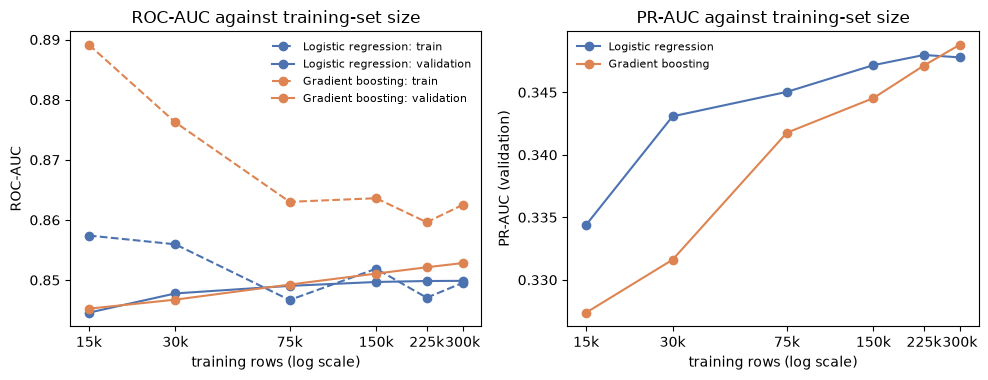

In [43]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from src.evaluation import size_learning_curve, plot_size_curves

curves = {
    "Logistic regression": size_learning_curve(
        lambda: LogisticRegression(C=1.0, max_iter=1000, random_state=SEED), data),
    "Gradient boosting": size_learning_curve(
        lambda: HistGradientBoostingClassifier(learning_rate=0.05, max_iter=600, max_leaf_nodes=15,
                                               min_samples_leaf=100, l2_regularization=1.0, early_stopping=True,
                                               validation_fraction=0.1, n_iter_no_change=20, random_state=SEED),
        data, scale=False),
}
for name, df_ in curves.items():
    print(name)
    print(df_.round(4).to_string())
    print()
for name, df_ in curves.items():
    df_.to_csv(PROJECT_ROOT / 'experiments' / f"learning_curve_size_{name.split()[0].lower()}.csv")
plot_size_curves(curves, path=FIG / "learning_curve_by_size.png")

**Reading the learning curves.** Logistic regression has converged. Its validation ROC-AUC rises from 0.845 with
15,000 training rows to 0.849 at 75,000 and then barely moves (0.850 with 300,000), and by then its training and
validation scores meet. More data of the same kind will not improve it: its remaining error is bias with respect to
these features, not variance. The training curve is jagged because it is measured on a 50,000-row sample, whose AUC
has a sampling error of about 0.004.

Gradient boosting behaves differently. With 15,000 rows its training AUC is 0.889 against a validation AUC of
0.845, a gap of 0.044 that is a clear variance problem: the flexible model memorises a small sample. As the data
grows the gap closes to about 0.010 and validation AUC climbs to 0.853, with each step smaller than the last
(+0.0018, +0.0010, +0.0007). Some variance remains, so more data would help a little, but the trend suggests that
doubling the data would add on the order of a thousandth of AUC, which is a rough extrapolation and not a
measurement.

The precision-recall panel adds a practical point. Logistic regression is the better model when data is scarce: it
leads boosting up to 225,000 rows, and boosting only draws level at the full 300,000. The small advantage of the
flexible model therefore depends on having a large dataset. For a smaller sample, such as a single clinic, a
regularised linear model would be the safer choice.

## 19. Which answers drive the predictions?

**Permutation importance** shuffles one survey column at a time among the validation people and measures how much
the model's ROC-AUC falls. A large fall means the model relies on that answer; a fall near zero means it does not.
It is computed through the whole pipeline, so imputation and encoding are included, and it is measured on held-out
data. One caveat: when two columns carry similar information (age and employment status, for example) shuffling
one of them is partly covered by the other, so importance can be shared and understated for each.

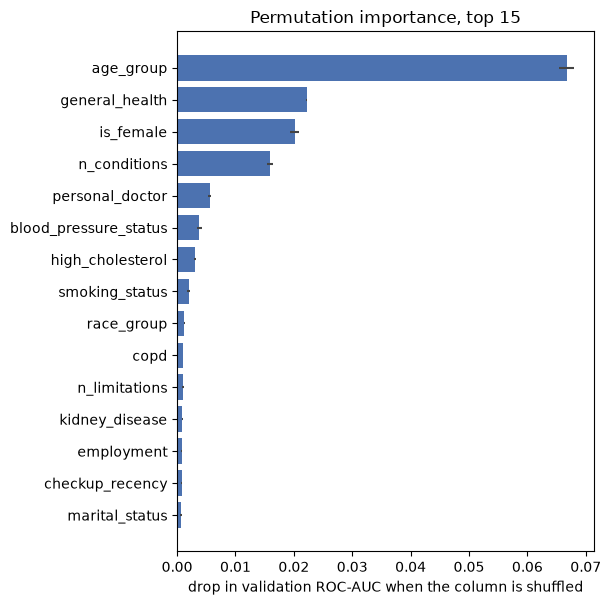

,roc_auc_drop,roc_auc_drop_sd,pr_auc_drop
age_group,0.0667,0.0013,0.0675
general_health,0.0222,0.0001,0.0512
is_female,0.0201,0.0007,0.0393
n_conditions,0.0159,0.0005,0.0324
personal_doctor,0.0056,0.0003,0.0126
blood_pressure_status,0.0038,0.0004,0.0102
high_cholesterol,0.0031,0.0002,0.0073
smoking_status,0.0020,0.0003,0.0044
race_group,0.0013,0.0001,0.0039
copd,0.0010,0.0001,0.0036


In [44]:
from src.evaluation import permutation_table, plot_importance, logistic_odds_table

imp = permutation_table(exp9["pipeline"], data["X_val"], data["y_val"], feature_columns(True), n_repeats=5)
plot_importance(imp, top=15, path=FIG / "permutation_importance.png")
imp.head(15).round(4)

**Reading the importance results.** Age dominates. Shuffling it costs 0.067 ROC-AUC, three times as much as the next
feature, in a model that is only 0.35 above chance to begin with. Self-rated general health (0.022), sex (0.020)
and the engineered count of conditions (0.016) follow. Beyond the top eleven each feature is worth about a
thousandth of AUC or less, which is another way of seeing why the model reaches a ceiling: most of what it knows
comes from four answers.

Two cautions apply. First, `n_conditions` ranks fourth, yet Experiment 11 showed that removing it before training
changed nothing. These do not contradict each other. Permutation importance measures how much a trained model
relies on a column, not how much information is lost if the column is absent; without it, the model recovers the
same pattern from the individual conditions the count summarises. Importance is also shared among correlated
inputs, so each one's number understates how much the group matters.

Second, `personal_doctor` ranks fifth, ahead of blood pressure and cholesterol, which is surprising for a risk
factor. A plausible reading is access to care. The outcome is "ever told by a doctor", so a person with no regular
doctor is less likely to have been diagnosed whatever their underlying disease. If so, part of what the model
learns is the chance of being diagnosed and not only the chance of having heart disease. This is a hypothesis that
the survey cannot test, but it fits the low disease rate (3.7 percent) and low recall found among the uninsured.

### The same question for the interpretable model

A logistic regression gives each input a coefficient. Numeric inputs were standardised, so the odds ratio for a numeric
input is the change in odds for a one-standard-deviation increase, holding the others fixed. For one-hot encoded
categories it is that category compared with the others on average (every category is kept and the L2 penalty shares the weight), so it is not a comparison with a single reference group.

In [45]:
logistic_odds_table(exp2["pipeline"], top=12)

,input,coefficient,odds ratio
0,is_female,-0.767,0.465
1,age_group,0.754,2.126
2,general_health,0.417,1.517
3,n_conditions,0.362,1.436
4,smoking_status_4.0,-0.301,0.740
5,race_group_2.0,-0.281,0.755
6,kidney_disease,0.265,1.304
7,personal_doctor_1.0,-0.263,0.769
8,blood_pressure_status_3.0,-0.262,0.769
9,high_cholesterol,0.258,1.294


**Reading the coefficients.** Logistic regression tells the same story with a direction attached. With the other
answers held fixed, being female is associated with roughly half the odds of reported heart disease (odds ratio
0.47). One standard deviation of age, about 18 years, multiplies the odds by 2.1. One standard deviation worse on
self-rated health, about one point on the five-point scale, multiplies them by 1.5, and a standard deviation more
in the count of conditions, about 1.7 conditions, by 1.4. Kidney disease raises the odds by about 30 percent, and
never having smoked is associated with odds about 26 percent lower.

These are associations in a cross-sectional survey, not causal effects. Race group is included only as a descriptive
covariate. Whether race should be an input to a clinical risk score is contested, and the report discusses it under
limitations, so its coefficient here should not be read as biological. The missing-value flags are left out of the
table because they come in perfectly opposite pairs, the encoder having split each into "missing" and "not missing"
columns, and several belong to groups of well under one percent of respondents, so their coefficients are not
clinical findings.